# Explaining the final model (xAI)

The final model (P6 in `final_stacker.ipynb`, validation macro-F1 0.9624) is a logistic regression on four inputs: **encoder v2** (BGE-M3 on whole texts), **Branch A** (XLM-R base, mean over 512-token windows), the window detector's **curves**, and the **Qwen** log-prob features. Because the model is linear in standardized features, every decision splits **exactly** into one contribution per input (`encoder/final_model.py`; for a linear model this equals SHAP with the mean as baseline). Everything here is on the fixed validation fold.

- **A. What the model relies on**: each input's share of the decisions, by domain and text length, and permutation importance per input.
- **B. Explanation cards**: single texts with the decision split into inputs, the p(AI) curves along the text and the text highlighted (`figures/final_model_explanations.html`).
- **C. Curves along the text**: how well the detector's curves locate the rewritten part (twin boundaries) and how detection depends on how lightly a text was rewritten.
- **D. Encoder word attributions (later)**: how a third highlight layer plugs into the cards.

In [1]:
import base64
import html
import io
import json
import os
import re
import sys
from pathlib import Path

import kagglehub
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import HTML, display
from sklearn.metrics import f1_score, roc_auc_score
from transformers import AutoTokenizer

sys.path.insert(0, str(Path("../cluster").resolve()))
from encoder.curve_features import HIGH, subsample
from encoder.data import LABELS, SEED, load_sets, prefix_key
from encoder.final_model import (CURVES_JOB, INPUTS, QWEN_JOB, contributions, fit_final, input_groups, input_table,
                                 margin, predict)
from encoder.qwen_features import fit_calibration, windows, with_p_ai
from encoder.stacking import read_parts

COMPETITION = "ai-generated-text-detection-hw3-ucu-ai-2026"
REPO = Path("..")
RESULTS = REPO / "cluster" / "results"
FIGURE_DIR = REPO / "figures"
TOKENIZER = "xlm-roberta-base"  # = FacebookAI/xlm-roberta-base (the detector's tokenizer)
SIZES = [64, 128, 256]
INPUT_COLORS = {"encoder v2": "#2a78d6", "Branch A": "#eb6834", "curves": "#1baf7a", "Qwen": "#eda100"}

sets = load_sets(kagglehub.competition_download(COMPETITION))
val = sets["val"].set_index("id", drop=False)
tokenizer = AutoTokenizer.from_pretrained(TOKENIZER)

X = {name: input_table(name, sets, REPO) for name in ("stacker", "val")}
model = fit_final(X["stacker"], sets["stacker"]["label"])
final_pred = pd.Series(predict(model, X["val"]), index=X["val"].index)
contribs = contributions(model, X["val"])
pd.DataFrame({"columns": {name: len(cols) for name, cols in input_groups(X["val"].columns).items()}}).T.assign(
    **{"validation macro-F1 (refitted)": round(f1_score(val["label"], final_pred.loc[val.index], average="macro"), 4)})

[transformers] PyTorch was not found. Models won't be available and only tokenizers, configuration and file/data utilities can be used.


,encoder v2,Branch A,curves,Qwen,validation macro-F1 (refitted)
columns,3,3,66,64,0.9624


## A. What the final model relies on
For each text, the model's score for a class is the sum of the four inputs' contributions, an intercept and the class weight. The table shows the mean absolute contribution of each input, for each class score and for the hard decision **fusion vs human** (the difference of the two scores), and each input's share of the total.

In [2]:
def contribution_shares(contribs):
    """Mean |contribution| of each input to each class score and to the fusion - human difference, with shares."""
    decisions = {f"{label} score": contribs[label] for label in LABELS}
    decisions["fusion − human"] = margin(contribs, "fusion", "human")
    mean_abs = pd.DataFrame({name: frame[INPUTS].abs().mean() for name, frame in decisions.items()}).T
    shares = mean_abs.div(mean_abs.sum(axis=1), axis=0).mul(100).add_suffix(" %")
    return mean_abs.join(shares)


contribution_shares(contribs).round(2)

,encoder v2,Branch A,curves,Qwen,encoder v2 %,Branch A %,curves %,Qwen %
human score,1.56,0.33,0.50,0.36,56.86,11.93,18.09,13.12
ai score,2.62,0.69,1.02,0.61,53.00,14.01,20.60,12.39
fusion score,1.84,0.58,0.69,0.43,51.95,16.42,19.52,12.11
fusion − human,2.18,0.61,0.63,0.49,55.69,15.55,16.21,12.54


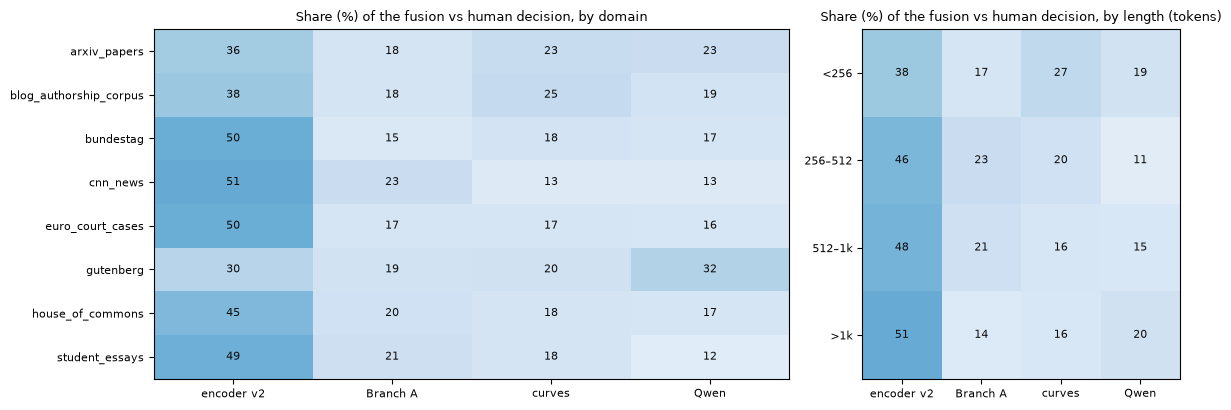

In [3]:
LENGTH_BINS = [0, 256, 512, 1024, np.inf]
LENGTH_LABELS = ["<256", "256–512", "512–1k", ">1k"]


def shares_by(contribs, groups):
    """Share (%) of each input in the |fusion − human| decision, averaged within each group of texts."""
    fusion_vs_human = margin(contribs, "fusion", "human")[INPUTS].abs()
    shares = fusion_vs_human.div(fusion_vs_human.sum(axis=1), axis=0).mul(100)
    return shares.groupby(groups.loc[shares.index]).mean()


n_tokens = np.exp(X["val"]["128_fine__log_tokens"]).round()
by_domain = shares_by(contribs, val["domain"])
by_length = shares_by(contribs, pd.cut(n_tokens, LENGTH_BINS, labels=LENGTH_LABELS)).rename(index=str)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw={"width_ratios": [8, 4]})
for ax, table, title in [(axes[0], by_domain, "by domain"), (axes[1], by_length, "by length (tokens)")]:
    ax.imshow(table.to_numpy(), cmap="Blues", vmin=0, vmax=100, aspect="auto")
    ax.set_xticks(range(len(INPUTS)), INPUTS, fontsize=8)
    ax.set_yticks(range(len(table)), table.index, fontsize=8)
    for (i, j), value in np.ndenumerate(table.to_numpy()):
        ax.text(j, i, f"{value:.0f}", ha="center", va="center", fontsize=8, color="white" if value > 55 else "#0b0b0b")
    ax.set_title(f"Share (%) of the fusion vs human decision, {title}", fontsize=9)
fig.tight_layout();

In [4]:
def push_to_truth(contribs, y_true):
    """Mean contribution of each input to score(true class) − score(strongest other class), per true class.

    Positive = the input pushes towards the right answer on average.
    """
    rows = {}
    for label in LABELS:
        ids = y_true.index[y_true == label]
        others = [other for other in LABELS if other != label]
        totals = {other: contribs[other].loc[ids].sum(axis=1) for other in others}
        strongest = pd.DataFrame(totals).idxmax(axis=1)
        pushes = pd.concat([margin(contribs, label, other).loc[strongest.index[strongest == other], INPUTS]
                            for other in others])
        rows[f"true {label} ({len(ids):,})"] = pushes.mean()
    return pd.DataFrame(rows).T


push_to_truth(contribs, val["label"]).round(2)

,encoder v2,Branch A,curves,Qwen
"true human (6,673)",3.67,0.47,0.29,0.17
"true ai (12,195)",4.25,1.08,1.67,0.68
"true fusion (8,368)",3.21,0.87,0.62,0.06


**Permutation importance per input**: shuffle all columns of one input together across validation texts and measure the drop in validation macro-F1 (5 shuffles). Unlike the contributions, this shows what the model *loses* without an input, so inputs that overlap with others can have large contributions but small importance.

In [5]:
N_REPEATS = 5


def permutation_importance(model, X, y, groups, seed=SEED):
    """Mean and std of the macro-F1 drop when the columns of each input are shuffled together."""
    base = f1_score(y, predict(model, X), average="macro")
    rng = np.random.default_rng(seed)
    rows = []
    for name, columns in groups.items():
        drops = []
        for _ in range(N_REPEATS):
            shuffled = X.copy()
            shuffled[columns] = X[columns].to_numpy()[rng.permutation(len(X))]
            drops.append(base - f1_score(y, predict(model, shuffled), average="macro"))
        rows.append({"input": name, "columns": len(columns), "macro-F1 drop": np.mean(drops), "std": np.std(drops)})
    return pd.DataFrame(rows).set_index("input").sort_values("macro-F1 drop", ascending=False)


importance = permutation_importance(model, X["val"], val.loc[X["val"].index, "label"].to_numpy(), input_groups(X["val"].columns))
importance.round(4)

,columns,macro-F1 drop,std
input,,,
encoder v2,3,0.5194,0.0013
curves,66,0.0116,0.0006
Branch A,3,0.0060,0.0003
Qwen,64,0.0039,0.0003


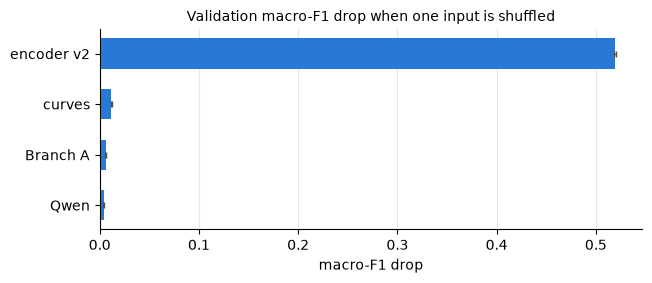

In [6]:
fig, ax = plt.subplots(figsize=(7, 2.6))
order = importance.sort_values("macro-F1 drop")
ax.barh(order.index, order["macro-F1 drop"], xerr=order["std"], color="#2a78d6", height=0.6,
        error_kw={"ecolor": "#52514e", "elinewidth": 1, "capsize": 2})
ax.set(title="Validation macro-F1 drop when one input is shuffled", xlabel="macro-F1 drop")
ax.grid(axis="x", color="#e6e6e3", linewidth=0.8)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)
ax.title.set_fontsize(10);

## B. Explanation cards
Each card explains one validation text:
- **header**: true label, domain, length, the previous final model's prediction (E2: Branch A + curves) and the final model's prediction with its probabilities;
- **left**: why the final model chose its class rather than the alternative (the true class if it was wrong, otherwise the runner-up): the score difference split into the four inputs, the intercept and the class weights;
- **right**: the detector's p(AI) along the text (64 / 128 / 256-token windows) and Qwen's calibrated p(AI) (128 tokens), with the true boundary of a fusion text (dashed) where its human twin is known;
- **text**: an excerpt (up to 250 words around the boundary or the most AI-like part), highlighted by one layer at a time: detector p(AI), Qwen p(AI), and encoder v2's word attributions once they exist (section D). **‖** marks the true boundary.

The gallery groups the cards into errors the final model fixed (compared with E2), errors that remain, and typical correct cases. It is saved as `figures/final_model_explanations.html`; three cards are shown below.

In [7]:
def boundary_char(fusion_text, human_text):
    """Character offset where the fusion text stops copying its human twin (end of the last copied word)."""
    copied = len(os.path.commonprefix([fusion_text.split(), human_text.split()]))
    word_ends = [m.end() for m in re.finditer(r"\S+", fusion_text)]
    return word_ends[copied - 1] if copied else 0


def bigram_overlap(fusion_text, human_text):
    """Share of the word bigrams of the fusion text's rewritten part that also occur in the twin's rest."""
    fusion_words, human_words = fusion_text.split(), human_text.split()
    copied = len(os.path.commonprefix([fusion_words, human_words]))
    fusion_rest, human_rest = fusion_words[copied:], human_words[copied:]
    fusion_bigrams, human_bigrams = set(zip(fusion_rest, fusion_rest[1:])), set(zip(human_rest, human_rest[1:]))
    return len(fusion_bigrams & human_bigrams) / max(len(fusion_bigrams), 1)


def twin_boundaries(df):
    """Boundary (character, token, share of the text) and rewrite overlap of fusion texts with one human twin in df."""
    humans = df[df["label"] == "human"]
    human_by_prefix = (humans.assign(prefix=prefix_key(humans["text"]))
                             .drop_duplicates("prefix", keep=False).set_index("prefix")["text"])
    fusion = df[df["label"] == "fusion"].assign(prefix=lambda d: prefix_key(d["text"]))
    fusion = fusion[fusion["prefix"].isin(human_by_prefix.index)]
    twins = human_by_prefix.loc[fusion["prefix"]].to_numpy()
    chars = [boundary_char(f, h) for f, h in zip(fusion["text"], twins)]
    enc = tokenizer(fusion["text"].tolist(), add_special_tokens=False, return_offsets_mapping=True, verbose=False)
    tokens = [int(np.searchsorted([start for start, _ in offsets], c)) for offsets, c in zip(enc["offset_mapping"], chars)]
    n_tok = np.array([len(ids) for ids in enc["input_ids"]])
    return pd.DataFrame({"domain": fusion["domain"].to_numpy(), "boundary_char": chars, "boundary_tok": tokens,
                         "n_tokens": n_tok, "boundary_share": np.array(tokens) / n_tok,
                         "bigram_overlap": [bigram_overlap(f, h) for f, h in zip(fusion["text"], twins)]},
                        index=pd.Index(fusion["id"].to_numpy(), name="id"))


def e2_predictions():
    """Validation labels of the previous final model E2 (Branch A + curves): saved probabilities x class weights."""
    probs = pd.read_csv(REPO / "outputs" / "curves" / f"final_probs_{CURVES_JOB}_val.csv", index_col="id")[LABELS]
    configs = json.loads((REPO / "outputs" / "curves" / f"best_configs_{CURVES_JOB}.json").read_text())
    w_human, w_fusion = configs["E2: Branch A + curves"]["class_weights"]
    return pd.Series(np.array(LABELS)[(probs.to_numpy() * [w_human, 1.0, w_fusion]).argmax(axis=1)], index=probs.index)


def qwen_val_windows(size=128):
    """Qwen windows of the validation set with p(AI) from a calibration fitted on the detector set."""
    chunks = {name: read_parts(RESULTS / QWEN_JOB, f"qwen_chunks_{name}.part*.csv.gz") for name in ("detector", "val")}
    calibration = fit_calibration(windows(chunks["detector"], size), sets["detector"].set_index("id")["label"], seed=SEED)
    return with_p_ai(windows(chunks["val"], size), calibration)


boundaries = twin_boundaries(val)
detector_curves = {size: read_parts(RESULTS / CURVES_JOB, f"curves_val_{size}.part*.csv.gz") for size in SIZES}
qwen_curves = qwen_val_windows()
e2_pred = e2_predictions()
final_probs = pd.DataFrame(model.predict_proba(X["val"]), columns=model.classes_, index=X["val"].index)[LABELS]
pd.Series({"validation texts": len(val), "fusion texts with a twin boundary": len(boundaries),
           "detector windows (128)": len(detector_curves[128]), "Qwen windows (128)": len(qwen_curves)}).to_frame("count").T

,validation texts,fusion texts with a twin boundary,detector windows (128),Qwen windows (128)
count,27236,6051,598669,567250


In [8]:
MAX_WORDS = 250
LAYER_COLORS = {"detector p(AI)": "235, 104, 52", "Qwen p(AI)": "237, 161, 0", "encoder v2 attribution": "42, 120, 214"}
CURVE_COLORS = {64: "#2a78d6", 128: "#eb6834", 256: "#1baf7a"}
ATTRIBUTION_FILES = sorted(RESULTS.glob("*/encoder_attributions.csv"))  # written by the part-3 job (section D)
attributions = pd.read_csv(ATTRIBUTION_FILES[-1]) if ATTRIBUTION_FILES else None


def char_scores(text, spans):
    """Mean score of the spans covering each character (NaN where none does); spans: char_start, char_end, score."""
    total, count = np.zeros(len(text)), np.zeros(len(text))
    for start, end, value in spans[["char_start", "char_end", "score"]].itertuples(index=False):
        total[start:end] += value
        count[start:end] += 1
    return np.divide(total, count, out=np.full(len(text), np.nan), where=count > 0)


def text_layers(text_id, text):
    """Per-character scores of every available highlight layer for one text, each scaled to [0, 1]."""
    layers = {
        "detector p(AI)": char_scores(text, detector_curves[128].query("id == @text_id").rename(columns={"p_ai": "score"})),
        "Qwen p(AI)": char_scores(text, qwen_curves.query("id == @text_id").rename(columns={"p_ai": "score"})),
    }
    if attributions is not None and (attributions["id"] == text_id).any():
        spans = attributions[attributions["id"] == text_id]
        layers["encoder v2 attribution"] = char_scores(text, spans.assign(score=spans["score"].clip(lower=0) / max(spans["score"].max(), 1e-9)))
    return layers


def excerpt(text, focus_char):
    """Word matches of an excerpt of at most MAX_WORDS words around focus_char."""
    words = list(re.finditer(r"\S+", text))
    if len(words) <= MAX_WORDS:
        return words
    centre = next((i for i, m in enumerate(words) if m.end() >= focus_char), len(words) - 1)
    start = min(max(0, centre - MAX_WORDS // 2), len(words) - MAX_WORDS)
    return words[start:start + MAX_WORDS]


def highlighted(text, words, scores, color, boundary):
    """HTML of an excerpt, each word's background alpha = its mean score; ‖ at the boundary."""
    parts = ["… "] if words[0].start() > 0 else []
    marked = False
    for match in words:
        if boundary is not None and not marked and match.start() >= boundary:
            parts.append('<b style="color:#d1495b; font-size:1.3em">‖</b> ')
            marked = True
        values = scores[match.start():match.end()]
        alpha = 0.0 if np.isnan(values).all() else float(np.nanmean(values))
        parts.append(f'<span style="background: rgba({color}, {alpha:.2f})">{html.escape(match.group())}</span> ')
    return "".join(parts) + ("…" if words[-1].end() < len(text.rstrip()) else "")

In [9]:
def alternative(text_id):
    """The class the decision is explained against: the true class if wrong, else the runner-up."""
    true, pred = val.loc[text_id, "label"], final_pred[text_id]
    if true != pred:
        return true
    scores = {label: contribs[label].loc[text_id].sum() for label in LABELS if label != pred}
    return max(scores, key=scores.get)


def card_figure(text_id):
    """Left: the score difference (prediction − alternative) split into inputs. Right: p(AI) along the text."""
    pred, other = final_pred[text_id], alternative(text_id)
    parts = margin(contribs, pred, other).loc[text_id, [*INPUTS, "intercept", "class weight"]]
    fig, (left, right) = plt.subplots(1, 2, figsize=(11, 2.9), gridspec_kw={"width_ratios": [4, 6]})
    colors = ["#2a78d6" if value >= 0 else "#eb6834" for value in parts]
    left.barh(parts.index[::-1], parts.to_numpy()[::-1], color=colors[::-1], height=0.6)
    left.axvline(0, color="#52514e", linewidth=0.8)
    for i, value in enumerate(parts.to_numpy()[::-1]):
        left.text(value, i, f" {value:+.2f} ", va="center", ha="left" if value >= 0 else "right", fontsize=7, color="#52514e")
    left.set_title(f"{pred} rather than {other}: score difference {parts.sum():+.2f}", fontsize=9)
    left.tick_params(labelsize=8)
    left.margins(x=0.25)
    for size, curve in detector_curves.items():
        windows_of_text = curve[curve["id"] == text_id]
        centre = (windows_of_text["tok_start"] + windows_of_text["tok_end"]) / 2 / windows_of_text["n_tokens"]
        right.plot(centre, windows_of_text["p_ai"], color=CURVE_COLORS[size], linewidth=1.5, label=f"detector {size}")
    qwen_text = qwen_curves[qwen_curves["id"] == text_id]
    right.plot((qwen_text["tok_start"] + qwen_text["tok_end"]) / 2 / qwen_text["n_tokens"], qwen_text["p_ai"],
               color="#eda100", linewidth=1.5, linestyle="--", label="Qwen 128")
    if text_id in boundaries.index:
        right.axvline(boundaries.loc[text_id, "boundary_share"], color="#52514e", linewidth=1, linestyle=":", label="true boundary")
    right.set(xlim=(0, 1), ylim=(-0.03, 1.03), xlabel="position in the text", ylabel="p(AI)")
    right.set_title("p(AI) along the text", fontsize=9)
    right.legend(fontsize=7, frameon=False, loc="center left", bbox_to_anchor=(1.0, 0.5))
    for ax in (left, right):
        ax.spines[["top", "right"]].set_visible(False)
        ax.tick_params(labelsize=8)
    fig.tight_layout()
    buffer = io.BytesIO()
    fig.savefig(buffer, format="png", dpi=110)
    plt.close(fig)
    return base64.b64encode(buffer.getvalue()).decode()


def mark(pred, true):
    """✓ for a correct prediction, ✗ for a wrong one."""
    return "✓" if pred == true else "✗"


def card_html(text_id):
    """One explanation card: header, decision figure, and the text with one <details> per highlight layer."""
    row = val.loc[text_id]
    probs = " · ".join(f"{label} {final_probs.loc[text_id, label]:.2f}" for label in LABELS)
    header = (f'<b>{row["label"]}</b> · {row["domain"]} · {len(row["text"].split())} words · '
              f'E2: <b>{e2_pred[text_id]}</b> {mark(e2_pred[text_id], row["label"])} → final: <b>{final_pred[text_id]}</b> '
              f'{mark(final_pred[text_id], row["label"])} <span style="color:#52514e">({probs})</span>')
    layers = text_layers(text_id, row["text"])
    boundary = boundaries.loc[text_id, "boundary_char"] if text_id in boundaries.index else None
    focus = boundary if boundary is not None else int(np.nanargmax(np.nan_to_num(layers["detector p(AI)"], nan=0)))
    words = excerpt(row["text"], focus)
    details = "".join(
        f'<details{" open" if i == 0 else ""} style="margin:6px 0"><summary style="cursor:pointer; color:#52514e">'
        f'highlight: {name}</summary><div style="line-height:1.7; margin-top:4px">'
        f'{highlighted(row["text"], words, scores, LAYER_COLORS[name], boundary)}</div></details>'
        for i, (name, scores) in enumerate(layers.items()))
    return (f'<div style="font-family: Inter, Helvetica, Arial, sans-serif; font-size: 13px; border: 1px solid #e6e6e3; '
            f'border-radius: 8px; padding: 12px 16px; margin: 14px 0; max-width: 1100px">{header}'
            f'<img style="width:100%; max-width:1050px; display:block; margin:8px 0" '
            f'src="data:image/png;base64,{card_figure(text_id)}">{details}</div>')

In [10]:
MIN_WORDS = 150
GALLERY = {
    "Errors the final model fixed (E2 was wrong)": [
        {"label": "fusion", "e2": "human", "final": "fusion", "twin": True},
        {"label": "fusion", "e2": "human", "final": "fusion"},
        {"label": "human", "e2": "fusion", "final": "human"},
        {"label": "human", "e2": "fusion", "final": "human"},
    ],
    "Errors that remain": [
        {"label": "fusion", "final": "human", "twin": True},
        {"label": "human", "final": "fusion"},
        {"label": "ai", "final": "fusion"},
    ],
    "Typical correct cases": [
        {"label": "fusion", "e2": "fusion", "final": "fusion", "twin": True},
        {"label": "human", "e2": "human", "final": "human"},
        {"label": "ai", "final": "ai"},
    ],
}


def pick(specs, seed=SEED):
    """One validation text id per spec (column -> value), at least MIN_WORDS words, no text twice."""
    info = val.assign(e2=e2_pred, final=final_pred, twin=val.index.isin(boundaries.index),
                      words=val["text"].str.split().str.len())
    picked = []
    for spec in specs:
        candidates = info[(info["words"] >= MIN_WORDS) & ~info.index.isin(picked)]
        for column, value in spec.items():
            candidates = candidates[candidates[column] == value]
        if len(candidates):
            picked.append(candidates.sample(1, random_state=seed).index[0])
    return picked


gallery_ids = {section: pick(specs) for section, specs in GALLERY.items()}
page = "".join(f'<h3 style="font-family: Inter, Helvetica, Arial, sans-serif; margin-top: 28px">{html.escape(section)}</h3>'
               + "".join(card_html(text_id) for text_id in ids) for section, ids in gallery_ids.items())
intro = ("<p style='font-family: Inter, Helvetica, Arial, sans-serif; color:#52514e; max-width:1100px'>Final model: "
         "logistic regression on encoder v2, Branch A, the detector's curves and Qwen (validation macro-F1 0.9624). "
         "Left: the score difference between the predicted class and the alternative, split into the inputs "
         "(blue = towards the prediction). Right: p(AI) along the text. Text: excerpt highlighted by one layer at a "
         "time (click to switch); ‖ = true boundary of a fusion text.</p>")
(FIGURE_DIR / "final_model_explanations.html").write_text(
    '<!DOCTYPE html><html><head><meta charset="utf-8"><title>Final model explanations</title></head>'
    '<body style="padding: 20px"><h2 style="font-family: Inter, Helvetica, Arial, sans-serif">'
    f'Explaining the final model on validation texts</h2>{intro}{page}</body></html>')
print(f"{sum(map(len, gallery_ids.values()))} cards saved to {FIGURE_DIR / 'final_model_explanations.html'}")

10 cards saved to ../figures/final_model_explanations.html



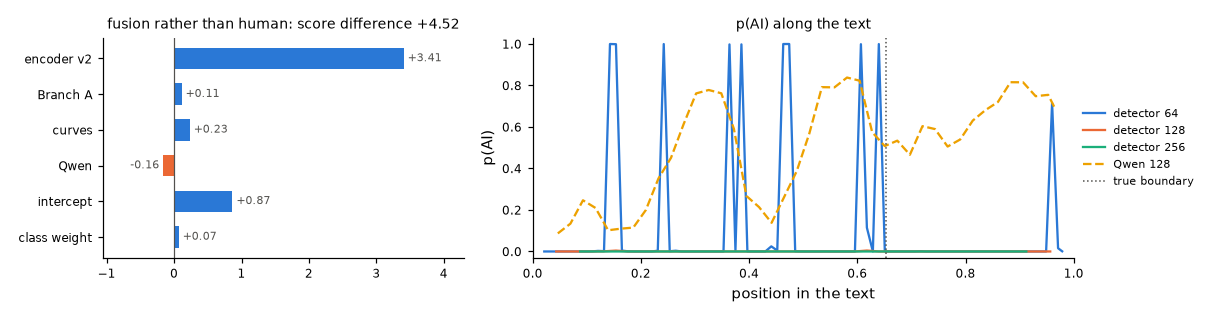
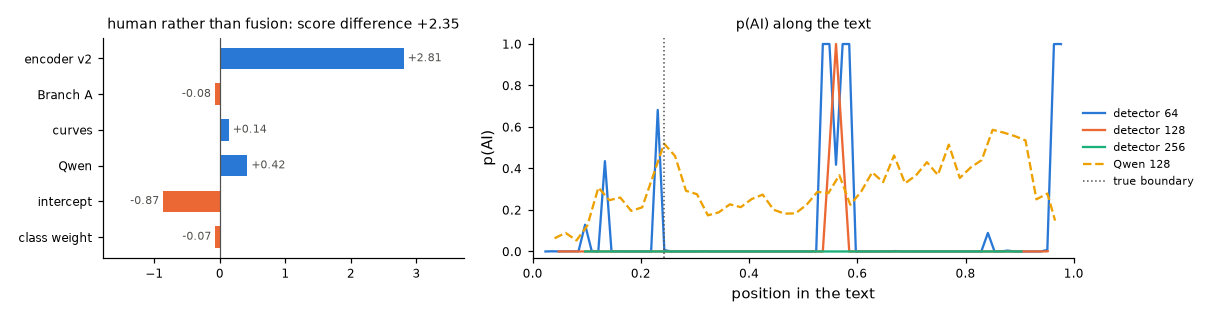
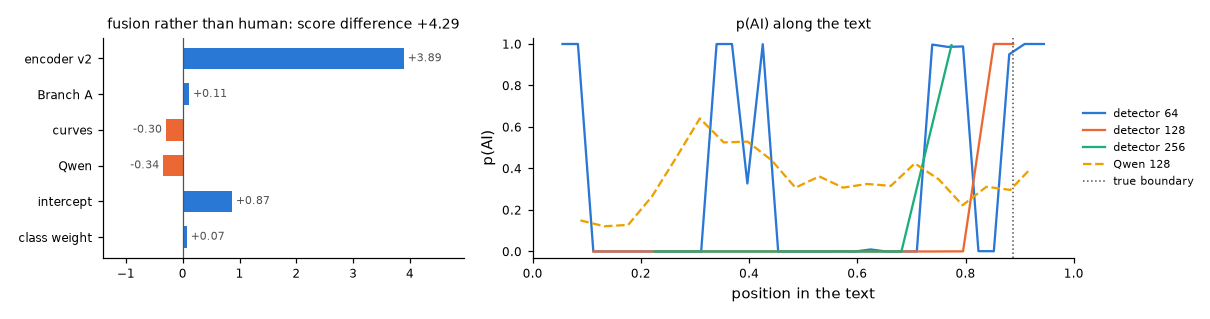

In [11]:
display(HTML("".join(card_html(ids[0]) for ids in gallery_ids.values())))

## C. Curves along the text
The curves are unchanged from `curve_stacker.ipynb`, so these results hold for the final model's curve input. For validation fusion texts with a known boundary (where the copied human text ends):
- **localisation**: where the most AI-like stretch starts vs the true boundary (`seg_start` = first token of its first window; the window centre is a second estimate, since a window must reach into the rewritten part before it fires);
- **window AUC**: p(AI) of windows after vs before the boundary (straddling windows excluded), per size and domain;
- **detection vs edit strength**: share of fusion texts with at least one non-overlapping high window (p(AI) > 0.5), by how much of the rewritten part's word bigrams also occur in the human twin (near 1 = lightly edited), with the same rule's false-alarm rate on human texts.

In [12]:
def localisation_errors(features, boundaries):
    """Per window size: share of twins with an AI-like stretch, and median / IQR of its start error."""
    rows = []
    for size in SIZES:
        has_segment = features.loc[boundaries.index, f"{size}_fine__seg_share"] > 0
        twins = boundaries[has_segment]
        seg_start = features.loc[twins.index, f"{size}_fine__seg_start"]
        estimates = {"window start": seg_start, "window centre": seg_start + (size - 2) / 2 / twins["n_tokens"]}
        for estimate, share in estimates.items():
            error = (share - twins["boundary_share"]).abs()
            error_tokens = error * twins["n_tokens"]
            rows.append({"size": size, "estimate": estimate, "twins with a stretch %": 100 * has_segment.mean(),
                         "median error (share)": error.median(), "IQR (share)": error.quantile(0.75) - error.quantile(0.25),
                         "median error (tokens)": error_tokens.median(),
                         "IQR (tokens)": error_tokens.quantile(0.75) - error_tokens.quantile(0.25)})
    return pd.DataFrame(rows).set_index(["size", "estimate"])


localisation_errors(X["val"], boundaries).round(3)

twins with a stretch %  median error (share)  IQR (share)  \
size estimate                                                                   
64   window start                   92.018                 0.064        0.112   
     window centre                  92.018                 0.024        0.074   
128  window start                   82.400                 0.104        0.129   
     window centre                  82.400                 0.029        0.057   
256  window start                   67.212                 0.167        0.168   
     window centre                  67.212                 0.046        0.075   

                    median error (tokens)  IQR (tokens)  
size estimate                                            
64   window start                    39.0          32.0  
     window centre                   15.0          35.0  
128  window start                    71.0          38.0  
     window centre                   20.0          30.0  
256  window start                   120.0          64.0  
     window centre                   33.0          41.0

In [13]:
def window_auc(curves, boundaries):
    """AUC of p(AI) for windows after vs before the boundary, per window size, overall and per domain."""
    rows = []
    for size, curve in curves.items():
        curve = curve.merge(boundaries[["boundary_tok", "domain"]], left_on="id", right_index=True)
        side = np.select([curve["tok_end"] <= curve["boundary_tok"], curve["tok_start"] >= curve["boundary_tok"]],
                         ["before", "after"], "straddle")
        curve = curve[side != "straddle"].assign(after=side[side != "straddle"] == "after")
        for domain, group in [("all", curve), *curve.groupby("domain")]:
            if group["after"].nunique() == 2:
                rows.append({"domain": domain, "size": size, "AUC": roc_auc_score(group["after"], group["p_ai"])})
    return pd.DataFrame(rows).pivot(index="domain", columns="size", values="AUC")


window_auc(detector_curves, boundaries).round(3)

size,64,128,256
domain,,,
all,0.681,0.684,0.691
arxiv_papers,0.739,0.742,0.737
blog_authorship_corpus,0.606,0.608,0.624
bundestag,0.718,0.726,0.740
cnn_news,0.589,0.624,0.680
euro_court_cases,0.674,0.669,0.664
house_of_commons,0.699,0.702,0.698
student_essays,0.804,0.819,0.846


In [14]:
OVERLAP_BINS = [0, 0.1, 0.3, 0.5, 0.7, 1.0]
OVERLAP_LABELS = ["0–0.1", "0.1–0.3", "0.3–0.5", "0.5–0.7", "0.7–1"]
FALSE_ALARMS = "human texts (false alarms)"
NON_OVERLAP = 4  # every 4th window of the size/4 grid: non-overlapping windows


def detected(curves, ids):
    """Per window size: whether each text has a non-overlapping window with p(AI) > HIGH."""
    return pd.DataFrame({size: subsample(curve[curve["id"].isin(ids)], NON_OVERLAP).groupby("id")["p_ai"].max().reindex(ids) > HIGH
                         for size, curve in curves.items()})


def detection_by_overlap(curves, boundaries, human_ids):
    """Detection rate (%) per bigram-overlap bin and window size, plus the false-alarm rate on human texts."""
    hits = detected(curves, boundaries.index)
    bins = pd.cut(boundaries["bigram_overlap"], OVERLAP_BINS, labels=OVERLAP_LABELS, include_lowest=True)
    table = hits.groupby(bins, observed=True).mean().mul(100).assign(texts=hits.groupby(bins, observed=True).size())
    table.index = table.index.astype(str).rename("bigram overlap")
    humans = detected(curves, human_ids)
    table.loc[FALSE_ALARMS] = [*humans.mean().mul(100), len(humans)]
    return table


detection = detection_by_overlap(detector_curves, boundaries, val.index[val["label"] == "human"])
detection.round(1)

,64,128,256,texts
bigram overlap,,,,
0–0.1,87.8,79.7,65.7,1958
0.1–0.3,97.6,92.6,86.1,459
0.3–0.5,97.6,93.7,85.0,826
0.5–0.7,96.4,90.6,75.3,1046
0.7–1,80.2,61.6,36.7,1762
human texts (false alarms),50.0,13.2,2.4,6673


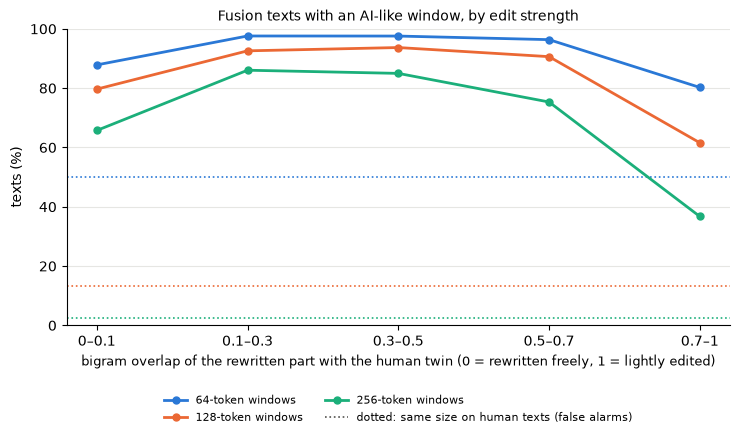

In [15]:
fig, ax = plt.subplots(figsize=(7.5, 4.6))
fusion_rows = detection.drop(index=FALSE_ALARMS)
for size in SIZES:
    ax.plot(fusion_rows.index, fusion_rows[size], color=CURVE_COLORS[size], linewidth=2, marker="o", markersize=5,
            label=f"{size}-token windows")
    ax.axhline(detection.loc[FALSE_ALARMS, size], color=CURVE_COLORS[size], linewidth=1.2, linestyle=":")
ax.plot([], [], color="#52514e", linewidth=1.2, linestyle=":", label="dotted: same size on human texts (false alarms)")
ax.set(title="Fusion texts with an AI-like window, by edit strength",
       xlabel="bigram overlap of the rewritten part with the human twin (0 = rewritten freely, 1 = lightly edited)",
       ylabel="texts (%)", ylim=(0, 100))
ax.grid(axis="y", color="#e6e6e3", linewidth=0.8)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=2)
ax.title.set_fontsize(10)
ax.xaxis.label.set_fontsize(9)
fig.tight_layout();

## D. Encoder v2 word attributions (later)
Encoder v2 carries most of the decision (section A), so the most informative extra layer is which words *it* reacted to. A cluster job can compute word-level attributions (e.g. Integrated Gradients) of encoder v2 for the gallery texts and write `cluster/results/<job>/encoder_attributions.csv` with columns `id, char_start, char_end, score` (one row per word or token span; higher = more evidence for the predicted class). Once that file is pulled, rerunning this notebook adds an **"encoder v2 attribution"** layer to every card (section B) automatically; nothing else changes.